# Section 1 – Data exploration and pre-processing

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.stem import LancasterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.sparse import csr_matrix
from langdetect import detect, DetectorFactory
from sklearn.decomposition import TruncatedSVD


In [2]:
numberStopwords=50
stemmization_Flag=True
lemmization_Flag=True

## 1. Data Exploration.
### a. How many different attribute values you observe in each feature? Is there any missing or duplicated data? (Referring to textual features)

In [3]:
#load datasets
train_data = pd.read_csv("data_supervised.csv", encoding="utf8")
target = pd.read_csv("target_supervised.csv", encoding="utf8")
unsupervised_data=pd.read_csv("data_unsupervised.csv", encoding="utf8")

#for each dataset, print for each column the number of elements missing
print("Missing values in supervised dataset:")
print(train_data.isnull().sum())
print("\nMissing values in target dataset:")
print(target.isnull().sum())
print("\nMissing values in unsupervised dataset:")
print(unsupervised_data.isnull().sum())
print("\nSupervised data: Counts of different attribute values observed in each feature:")
print(train_data.nunique())
print("supervised dataset shape:", train_data.shape)
print("\nUnsupervised data: Counts of different attribute values observed in each feature:")
print(unsupervised_data.nunique())
print("unsupervised dataset shape:", unsupervised_data.shape)

Missing values in supervised dataset:
author         0
subreddit      0
created_utc    0
body           0
dtype: int64

Missing values in target dataset:
author    0
gender    0
dtype: int64

Missing values in unsupervised dataset:
author         0
subreddit      0
created_utc    0
body           2
dtype: int64

Supervised data: Counts of different attribute values observed in each feature:
author           5000
subreddit        3468
created_utc    278142
body           289608
dtype: int64
supervised dataset shape: (296042, 4)

Unsupervised data: Counts of different attribute values observed in each feature:
author          15000
subreddit        3970
created_utc    715561
body           828126
dtype: int64
unsupervised dataset shape: (1107946, 4)


Unsupervised_data.csv has 2 comments missing here we remove them

In [4]:
unsupervised_data = unsupervised_data[unsupervised_data['body'].notnull()]
print(unsupervised_data.isnull().sum())

author         0
subreddit      0
created_utc    0
body           0
dtype: int64


Count duplicates

In [5]:
print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())
print(target.duplicated().sum())

7
256137
0


Deletion of duplicated rows

In [6]:
train_data=train_data.drop_duplicates()
unsupervised_data=unsupervised_data.drop_duplicates()
print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())  
print(target.duplicated().sum())  

0
0
0


### 2a Uniform text formats
(In the project guidelines this was step 2a but we prefered performing this before checking for the comments' language)
* removing all links 
* removing all characters that are not letters (from the english alphabet) or whitespace
* transform all characters to lowercase
* remove empty comments (or the ones with only whitespaces)

In [7]:
train_data['body'] = train_data['body'].str.lower()#to lowercase
train_data['body'] = train_data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs
train_data['body'] = train_data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters and whitespace
train_data = train_data[train_data['body'].str.strip().astype(bool)]#remove comments with only whitespace
train_data = train_data.dropna()#remove empty comments

### b. How does the empirical distribution of the number of characters in each comment look like? How is the distribution of the number of comments per author? Is the supervised dataset balanced between male and female? Are there only comments in English

Empirical distribution of the number of characterst in each comment

train data


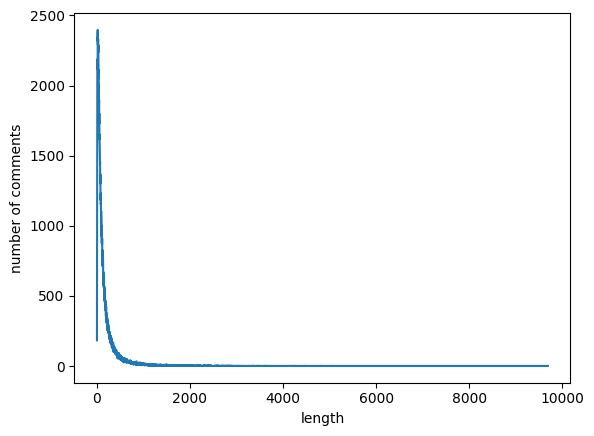

filtered train data


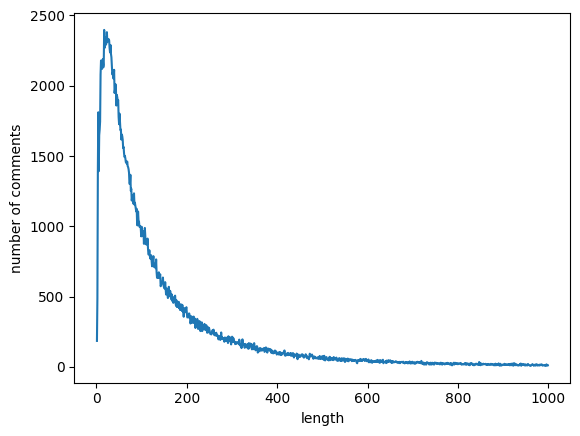

unsupervised data


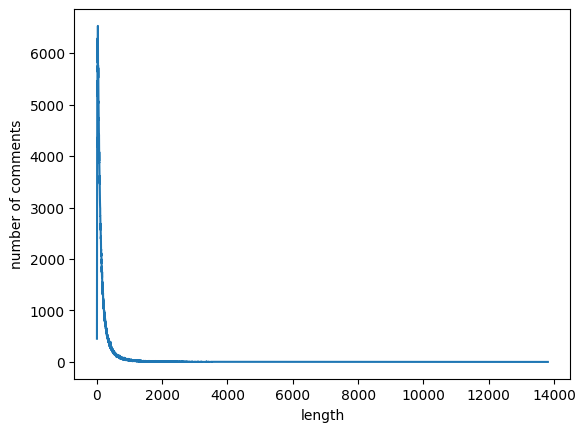

filtered unsupervised data


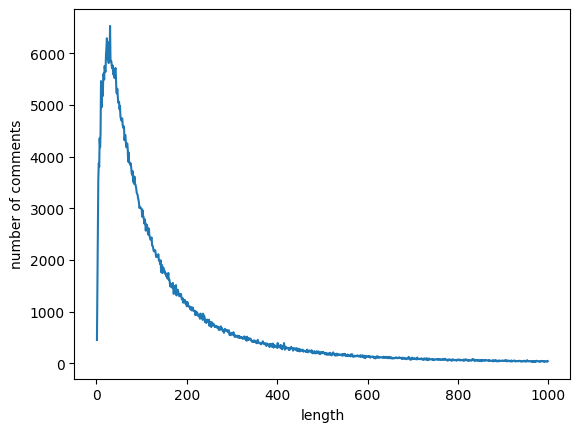

In [8]:
def plotEmpiricalDistributionNumberOfComments(data):

    #we can define a series that has the length as an index and the number of comments that match the length as the value
    countForLenght=data.groupby('length').count()['body']

    #print(countForLenght.max)

    x = countForLenght.index
    y =  countForLenght.values

    df = pd.DataFrame({
        'length' : x, #'length' : x[0:1000], 
        'number of comments' : y#[0:1000]
    })

    plt.figure()
    sns.lineplot(
        data = df, # which dataframe you want to use as the source data
        x = 'length', # which column to use for x-axis
        y = 'number of comments', # which column to use for y-axis
        ax = plt.gca() # assign this plot to current axis, not mandatory in this case
    )
    plt.show()

train_data['length'] = train_data['body'].astype(str).apply(len)
unsupervised_data['length'] = unsupervised_data['body'].astype(str).apply(len)

print("train data")
plotEmpiricalDistributionNumberOfComments(train_data)
print("filtered train data")
plotEmpiricalDistributionNumberOfComments(train_data[train_data['length'] < 1000])
print("unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data)
print("filtered unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data[unsupervised_data['length'] < 1000])


distribution of the number of comments per author

train data author distribution without outliers


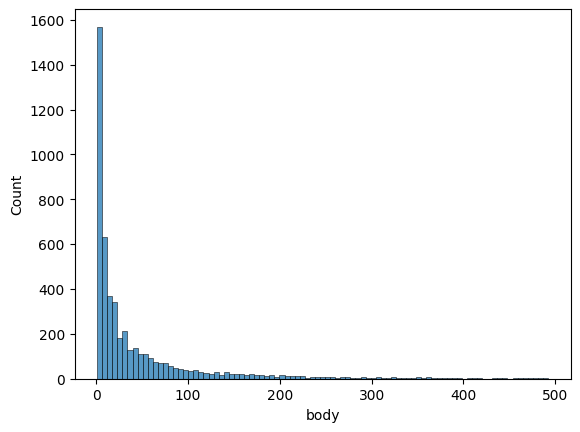

unsupervised data author distribution without outliers


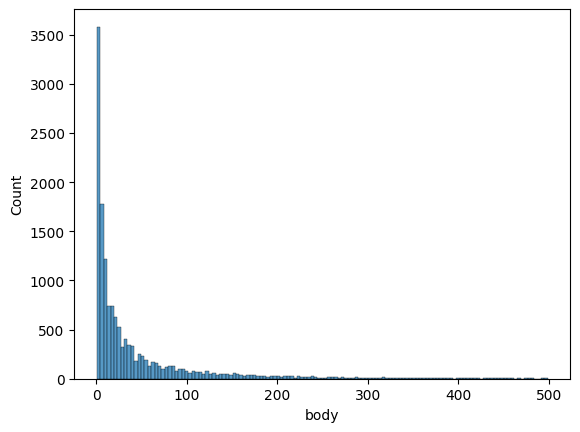

In [9]:
print("train data author distribution without outliers")
plt.figure()
sns.histplot(
    train_data.groupby('author').count()['body'][train_data.groupby('author').count()['body'] < 500]
)
plt.show()

print("unsupervised data author distribution without outliers")
plt.figure()
sns.histplot(
    unsupervised_data.groupby('author').count()['body'][unsupervised_data.groupby('author').count()['body'] < 500]#TODO ricontrollare sta roba
)
plt.show()


Is the supervised dataset balanced between male and female?

In [10]:
print(target.groupby('gender').count())
print(pd.merge(target,train_data).groupby('gender')['author'].count())

        author
gender        
0         3651
1         1349
gender
0    227337
1     67129
Name: author, dtype: int64


Are there only comments in English? 

In [11]:
DetectorFactory.seed = 0 

train_data['body'] = train_data['body'].fillna('').astype(str)
train_data = train_data[train_data['body'].str.strip().astype(bool)]#removing comments with only whitespace

langs = []
for text in train_data['body']:
    # if not text.strip():
    #     langs.append("empty")
    # else:
    try:
        langs.append(detect(text))
    except:
        langs.append("error")

train_data['language'] = langs

print("Number of comments per language:")
counts = train_data['language'].value_counts()
print(counts)

#save a filtered version of the dataset with only english comments
train_data_en = train_data[train_data["language"] == "en"]

Number of comments per language:
language
en    265950
cy      2606
af      2275
so      2238
fr      1837
da      1617
nl      1543
no      1535
it      1501
tl      1279
et      1136
ca       989
tr       980
sv       901
id       873
es       872
pl       716
fi       716
ro       673
pt       595
sw       591
sq       523
hr       468
de       445
sl       440
sk       320
cs       270
lt       170
vi       168
lv       131
hu       108
Name: count, dtype: int64


In [12]:
# ambigui = []

# for i, commento in enumerate(train_data["body"]):
#     try:
#         langs = detect_langs(commento)
#         best = langs[0]  # lingua con la probabilità più alta
#         if best.prob < 0.80:   # soglia di confidenza
#             ambigui.append((i, commento[:100], langs))  # salvo i casi incerti
#     except:
#         ambigui.append((i, commento[:100], "Errore"))

# # Mostra i primi 10 casi incerti
# for riga in ambigui[:10]:
#     print(riga)

## 2. Data Cleaning and text standardization.
Note that step 2a was executed previosly (Uniform text formats)
### b. Stop words are not contributing much to our ML tasks, such as "the", "a", since they carry very little information. Take care of these kinds of words.

In [13]:
#we consider the most frequent words as stopwords
MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)
#removing 
for word in MostFrequentWords:
    train_data['body']=train_data['body'].str.replace(rf'\b{word}\b', '', regex=True)
MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)


['the', 'to', 'a', 'i', 'and', 'of', 'you', 'it', 'that', 'is', 'in', 'for', 'but', 'on', 'have', 'with', 'be', 'not', 'my', 'was', 'this', 'are', 'if', 'as', 'its', 'they', 'just', 'like', 'so', 'or', 'your', 'at', 'me', 'he', 'dont', 'im', 'do', 'what', 'can', 'about', 'all', 'would', 'one', 'people', 'get', 'out', 'from', 'up', 'an', 'more']
['when', 'there', 'think', 'we', 'no', 'because', 'them', 'some', 'really', 'how', 'know', 'time', 'will', 'who', 'had', 'her', 'by', 'good', 'she', 'then', 'has', 'their', 'than', 'his', 'were', 'youre', 'thats', 'only', 'much', 'also', 'even', 'other', 'want', 'well', 'him', 'make', 'go', 'now', 'way', 'see', 'been', 'too', 'being', 'could', 'any', 'something', 'still', 'ive', 'which', 'going']


### c. Reduce words to their base or root form using Stemming/Lemmatization. This helps in reducing inflected words to a common base form.

In [14]:
#lemmization
def lemmatize_text(text,lemmatizer):
    tokens = word_tokenize(text)    
    # Lemmatize each token
    lemmatized_words = []
    for word in tokens:
        lemmatized_word = lemmatizer.lemmatize(word)
        lemmatized_words.append(lemmatized_word)
    lemmatized_text = ' '.join(lemmatized_words)
    return lemmatized_text

def lemmization(df):
    lemmatizer = WordNetLemmatizer()

    for index, row in df.iterrows():
        lemmatized_result = lemmatize_text(row['body'],lemmatizer)  # Process each row
        df.at[index, 'body'] = lemmatized_result

if lemmization_Flag:
    lemmization(train_data)

In [15]:
# Print the resulting DataFrame
print(train_data['body'][0])
print(train_data.shape)

think wed nearly much fanfiction picture shipping banban lyro saying
(294466, 6)


In [16]:
#stemming
def stemmer_text(text,stemmer):
    tokens = word_tokenize(text)
    stemmer_words = []
    for word in tokens: 
        stemmer_words.append(stemmer.stem(word))
    
    stemmed_text = ' '.join(stemmer_words)
    return stemmed_text

def stemmization(df):
    stemmer = LancasterStemmer()
    for index, row in df.iterrows():
        stemmed_result = stemmer_text(row['body'],stemmer)
        df.at[index, 'body'] = stemmed_result

if stemmization_Flag:
    stemmization(train_data)

In [17]:
print(train_data['body'][0])

think wed near much fanfict pict ship banb lyro say


## 3 Text vectorization
### a. Group and join all comments of the same author.

In [18]:
#grouping by the author
train_data=train_data[['author','body']].groupby('author').agg(' '.join).reset_index()
print(train_data.head(3))

     author                                               body
0    -Jared  neil diamond sweet carolin chiropract went rel...
1   -Peeter                                      read faq real
2  -evasian  receiv deathad black edit yesterday tri althou...


### b. ML algorithms struggle to handle directly the raw textual data. You are required to convert the text into numerical representations (vectors) through Bag of Words (BoW).

In [19]:
vectorizerCount = CountVectorizer()
vectorizerCount.fit(train_data['body'])
vectorized_bow = vectorizerCount.transform(train_data['body'])
print(vectorized_bow.shape)

(4997, 104797)


### c. Associate each word in each user/comment with its TF-IDF value (Term Frequency-Inverse Document Frequency). Can you observe and explain the differences between the numerical representations generated by BoW and TF-IDF?

In [20]:
vectorizerTfidf = TfidfVectorizer()
vectorizerTfidf.fit(train_data['body'])
vectorized_TF_IDF = vectorizerTfidf.transform(train_data['body'])
print(vectorized_TF_IDF.shape)

(4997, 104797)


## 4. Reduce the complexity of your dataset.
~~Reduce the number of features with PCA. Do not straightly perform PCA on the entire dataset because the number of features is large. Keep the first 1000 components, initializing PCA and fitting as well as transforming the dataset again. If the cumulative explained variance is lower than your choice, increase gradually the number of components.~~
Instead of using PCA we decided to use TruncatedSVD because it s can work with sparse matrices efficiently.

Cumulative explained variance with 2500 components: 83.54%


Text(0.5, 1.0, 'Explained Variance vs. Number of Components')

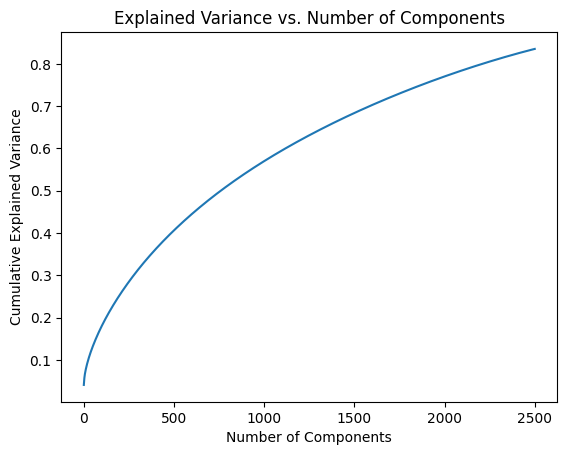

In [26]:
#pca=PCA(n_components=PCA_number_components,random_state=42,)
#pca.fit(vectorizerTfidf)

n_components = 2000
svd = TruncatedSVD(n_components=n_components, random_state=42)
X_reduced = svd.fit_transform(vectorized_TF_IDF)

explained_var = np.sum(svd.explained_variance_ratio_)
print(f"Cumulative explained variance with {n_components} components: {explained_var:.2%}")

#Plot of explained variance ratio
plt.figure()
plt.plot(np.cumsum(svd.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs. Number of Components')

In [22]:
#DF from reduced data
df_reduced = pd.DataFrame(X_reduced)
df_reduced.insert(0, "author", train_data["author"].values)

#Saving reduced data to csv
df_reduced.to_csv("X_reduced_svd.csv", index=True)
print(df_reduced[1])
print("File salvato come X_reduced_svd.csv")

0      -0.018785
1       0.002621
2      -0.039670
3      -0.015226
4       0.009816
          ...   
4992   -0.011988
4993    0.007691
4994   -0.077707
4995   -0.017348
4996   -0.000104
Name: 1, Length: 4997, dtype: float64
File salvato come X_reduced_svd.csv


In [23]:
# carico il file con le etichette (deve avere colonne ['author', 'gender'])
df_labels = pd.read_csv("target_supervised.csv")
#puliscom le colonne author
df_reduced['author'] = df_reduced['author'].str.strip().str.lower()
df_labels['author'] = df_labels['author'].str.strip().str.lower()


# unisco sul campo 'author'
df_final = pd.merge(df_reduced, df_labels, on="author", how="inner")

# porto 'gender' in prima colonna
cols = ['gender'] + [c for c in df_final.columns if c != 'gender']
df_final = df_final[cols]

# salvo il dataset pronto
df_final.to_csv("X_reduced_with_labels.csv", index=False)



In [24]:
#df_reduced['author'].duplicated().sum()
df_labels['author'].duplicated().sum()
# autori presenti in X_reduced ma non in labels
missing_in_labels = set(df_reduced['author']) - set(df_labels['author'])
print("Autori mancanti in labels:", missing_in_labels)

# autori presenti in labels ma non in X_reduced
missing_in_reduced = set(df_labels['author']) - set(df_reduced['author'])
print("Autori mancanti in X_reduced:", missing_in_reduced)



Autori mancanti in labels: set()
Autori mancanti in X_reduced: {'gearhead90', 'slendermanx', 'blaxk'}


In [25]:
# # describe how much of the dataset variability is indicated by a given amount of features
# explained_variance = pca.explained_variance_ratio_

# # evaluate the total dataset variability while increasing the variables
# cumul_exp_var = np.cumsum(explained_variance)

# # percentage value to better understand the best number of components
# perc_cumul_exp_var = cumul_exp_var * 100

# # make the plot of cumulative explained variance wrt number of components

# plt.figure(figsize=(5, 3.5))
# plt.plot(perc_cumul_exp_var, marker='o')
# plt.xlabel('# Principal Components (PCs)')
# plt.ylabel('Cumulative explained variance [%]')
# plt.xticks([i for i in range(PCA_number_components)], [i for i in range(1,PCA_number_components+1)])
# plt.grid()
# plt.title(f'{(PCA_number_components/2)-1} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)], 2)}% of $\sigma^2$')
# plt.tight_layout()
# plt.show()

# print(perc_cumul_exp_var[-1])
# pca_result = pca.transform(vectorizerTfidf)

# dfPCA=pd.DataFrame(pca_result)
# dfPCA.to_csv("PCA.csv")
# print(dfPCA.shape)